# Imports and Set up

In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import auc
#Log in to huggingface hub
from huggingface_hub import login
import os
from dotenv import load_dotenv
from transformers import AutoTokenizer, AutoModelForCausalLM, logging, pipeline
from datasets import load_dataset
import json
from scipy.sparse.csgraph import connected_components
load_dotenv()
login(token = os.getenv("HFToken"))
model_id = "meta-llama/Llama-3.2-1B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_id,padding_side="left")
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(model_id, device_map="cuda:0",dtype=torch.bfloat16)
ds = load_dataset("rajpurkar/squad")
pipe = pipeline("text-classification", model="microsoft/deberta-large-mnli")
logging.set_verbosity_info()
#HFToken = [your token] in .env

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

In [3]:
""" Official evaluation script for v1.1 of the SQuAD dataset. """

import re
import string
from collections import Counter


def normalize_answer(s):
    """Lower text and remove punctuation, articles and extra whitespace."""

    def remove_articles(text):
        return re.sub(r"\b(a|an|the)\b", " ", text)

    def white_space_fix(text):
        return " ".join(text.split())

    def remove_punc(text):
        exclude = set(string.punctuation)
        return "".join(ch for ch in text if ch not in exclude)

    def lower(text):
        return text.lower()

    return white_space_fix(remove_articles(remove_punc(lower(s))))


def f1_score(prediction, ground_truth):
    prediction_tokens = normalize_answer(prediction).split()
    ground_truth_tokens = normalize_answer(ground_truth).split()
    common = Counter(prediction_tokens) & Counter(ground_truth_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0
    precision = 1.0 * num_same / len(prediction_tokens)
    recall = 1.0 * num_same / len(ground_truth_tokens)
    f1 = (2 * precision * recall) / (precision + recall)
    return f1

In [113]:
#Prompt Generation
prompt = [[
    {
        "role": "system",
        "content":"Answer in as few words as possible. Output only the entity name and nothing else."
        #"content": "You are a precise calculator. Output ONLY the final numerical answer. Do not include words, units, explanations, or punctuation."
    },
    {
        "role": "user",
        "content":  f"Context\n{context}\nQuestion:\n{question}"
    }
]for question, context in zip(ds["train"]["question"],ds["train"]["context"])]

In [5]:
def input_batch(batch,size):
    input = tokenizer.apply_chat_template(
        prompt[batch*size:(batch+1)*size],
        tokenize = True,
        add_generation_prompt=True,
        padding=True,
        return_tensors="pt",
        clean_up_tokenization_spaces=False
    ).to("cuda:0")
    input_length = input["input_ids"].shape[1]
    return(input,input_length,size)

In [133]:
def output_batch(input, input_length,questions,offset):
    raw_output = model.generate(
        input_ids = input['input_ids'],
        attention_mask = input['attention_mask'],
        max_new_tokens= 100,
        do_sample=True,
        temperature=0.7,
        pad_token_id=tokenizer.pad_token_id,
        tokenizer=tokenizer,
        return_dict_in_generate=True,
        output_logits=True,
        output_scores=True
        )
    output = raw_output.sequences
    return(output,raw_output)

In [7]:
def f1score(output,input_length,questions,offset):
    predictions = []
    for i in range(questions):
       predictions.append(tokenizer.decode(output[i][input_length:],skip_special_tokens=True,clean_up_tokenization_spaces=True))
    f1 = torch.zeros(questions)
    for i in range(questions):
        if  (f1_score(predictions[i],ds["train"]["answers"][offset+i]["text"][0]) > 0.5):
            f1[i] = 1
        else:
            f1[i] = 0
    f1 = f1.cpu()
    return(f1)

In [8]:
def coscore(raw_output,questions):
    logits = raw_output.scores[-50:]
    tensor_logits = torch.stack(logits)
    prob = tensor_logits.softmax(dim=2)
    confidence = torch.zeros(questions)
    max_prob, max_ids = torch.max(prob,dim=2)
    confidence = torch.prod(max_prob,dim=0).cpu()
    return(confidence)

# Code Execution

In [161]:
f1l = []
col = []
size = 10
batch = 1000
for i in range(0,batch):
    input, input_length, questions = input_batch(i,size)
    output, raw_output = output_batch(input,input_length,questions,i*size)
    f1l.append(f1score(output,input_length,questions,i*size))
    col.append(coscore(raw_output,questions))
    if (i+1)%100 == 0:
        print("batch",i+1)
f1l = torch.cat(f1l).numpy()
col = torch.cat(col).numpy()

batch 100
batch 200
batch 300
batch 400
batch 500
batch 600
batch 700
batch 800
batch 900
batch 1000


In [ ]:
lic = -np.log(col)#log inverse confidence
correct = f1l
plt.plot(lic,correct,"ro",alpha=0.003)
plt.title("Correct vs -log(Probability)")
plt.ylabel("Correct")
plt.xlabel("-log(Probability)")
plt.show()

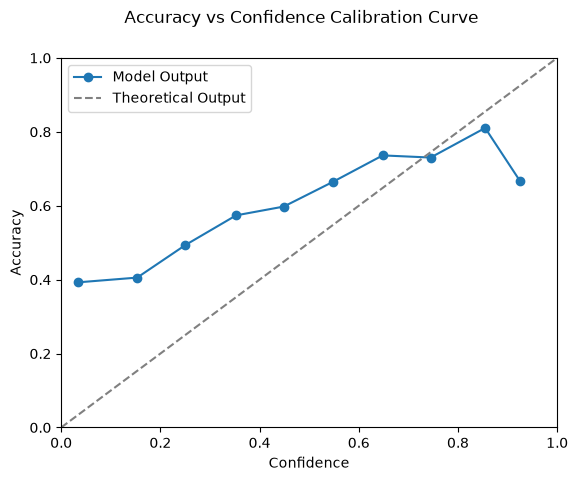

In [163]:
bin = np.linspace(0,1,11)
order = np.digitize(col,bin)-1
af1 = []
aco = []
for i in range(10):
    mask = order == i
    if mask.sum() > 0:
        af1.append(f1l[mask].mean())
        aco.append(col[mask].mean())
plt.xlim(0,1)
plt.ylim(0,1)
plt.suptitle("Accuracy vs Confidence Calibration Curve")
plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.plot(aco,af1,'o-',label="Model Output")
plt.plot([0,1],[0,1],'--',color='gray',label="Theoretical Output")
plt.legend()
plt.show()

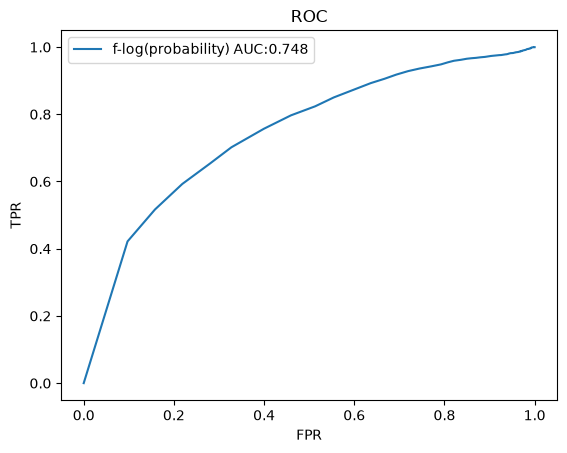

In [164]:
tpr = []
fpr = []
for i in np.linspace(lic.min(), lic.max(), 200):
    mask = lic < i
    tpr.append(correct[mask].sum()/correct.sum())
    fpr.append((1-correct)[mask].sum()/(batch*size-correct.sum()))
plt.title("ROC")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.plot(fpr,tpr,label=f"f-log(probability) AUC:{round(auc(fpr,tpr),3)}")
plt.legend()
plt.show()

In [165]:
score = np.array(tpr)- np.array(fpr)
mask = lic < ((lic.max()-lic.min())*score.argmax()/199)
ac = (correct[mask].sum()+(1-correct)[~mask].sum())/(size*batch)
print(ac)

0.6938


# Semantic Entropy testing

In [361]:
f1_list = []
o_list = []
size = 10
batch = 1000
rep = 10
for t in range(rep):
    f1l = []
    ol = []
    for i in range(batch):
        input, input_length, questions = input_batch(i,size)
        output, raw_output = output_batch(input,input_length,questions,i*size)
        f1l.append(f1score(output,input_length,questions,i*size))
        ol.extend([tokenizer.decode(k[input_length:],skip_special_tokens=True,clean_up_tokenization_spaces=True) for k in output])
        if (i+1)%(round(500)) == 0:
            print("batch",i+1)
    f1_list.append(torch.cat(f1l).numpy())
    o_list.append(ol)
f1_avg = np.mean(f1_list, axis=0)

batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000
batch 500
batch 1000


In [ ]:
o_array = np.array(o_list).T
idx = [(t,k,f) for t in range(len(o_array)) for k in range(rep) for f in range(rep) if f != k]
pairs = [{"text":o_array[t][k] ,"text_pair":o_array[t][f]} for (t,k,f) in idx]
if len(pairs) > 10000:
    result = []
    for i in range(100):
        result.extend(pipe(pairs[(i*len(pairs)//100):((i+1)*len(pairs)//100)], batch_size=32))
        print(i,"% done")
else:
    result = pipe(pairs, batch_size=32)
result = np.array(result).reshape(-1,rep-1)
result = [result[t][k]['label'] == 'ENTAILMENT' for t in range(len(result)) for k in range(rep-1)]
result = np.array(result).reshape(-1,rep-1)
maps = np.zeros((int(len(result)/rep),rep,rep),dtype = bool)
for t in range(int(len(result)/rep)):
    for k in range(rep):
        for f in range(rep):
            if k == f:
                maps[t][k][f] = True
            elif f < k:
                maps[t][k][f] = result[rep*t+k][f]
            else: 
                maps[t][k][f] = result[rep*t+k][f-1]


In [368]:
clusters = [np.bincount(t) for t in  np.array([
    connected_components(maps[t], directed=True, connection='strong')[1] for t in range(len(maps))
])]
semantic_entropy = np.array([np.sum(t/rep * (-np.log(t/rep))) for t in clusters])

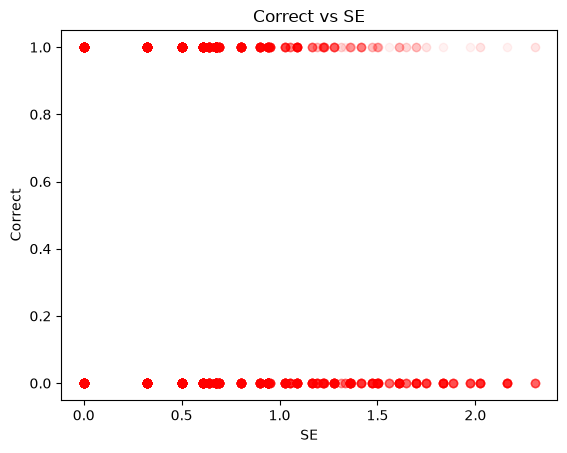

In [390]:
lic = semantic_entropy#log inverse confidence
correct = f1_avg > 0.5
plt.plot(lic,correct,"ro",alpha=0.05)
plt.title("Correct vs SE")
plt.ylabel("Correct")
plt.xlabel("SE")
plt.show()

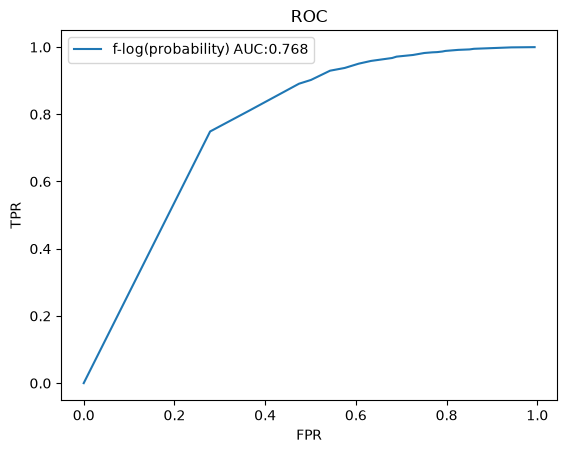

In [391]:
tpr = []
fpr = []
for i in np.linspace(lic.min(), lic.max(), 200):
    mask = lic < i
    tpr.append(correct[mask].sum()/correct.sum())
    fpr.append((1-correct)[mask].sum()/(batch*size-correct.sum()))
plt.title("ROC")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.plot(fpr,tpr,label=f"f-log(probability) AUC:{round(auc(fpr,tpr),3)}")
plt.legend()
plt.show()

In [371]:
score = np.array(tpr)- np.array(fpr)
mask = lic < ((lic.max()-lic.min())*score.argmax()/199)
ac = (correct[mask].sum()+(1-correct)[~mask].sum())/(size*batch)
print(ac)

0.7409
